# Real Data SPX Implied Volatility

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.optimize import brentq

In [ ]:
def black_scholes_price(S0, K, r, sigma, T, option_type="call"):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    if option_type == "call":
        price = (
            S0 * norm.cdf(d1)
            - K * np.exp(-r * T) * norm.cdf(d2)
        )

    elif option_type == "put":
        price = (
            K * np.exp(-r * T) * norm.cdf(-d2)
            - S0 * norm.cdf(-d1)
        )

    else:
        raise ValueError("option_type must be 'call' or 'put'")

    return price

In [ ]:
def implied_volatility(
    market_price,
    S0,
    K,
    r,
    T,
    option_type="call"
):

    def objective(sigma):
        model_price = black_scholes_price(
            S0=S0,
            K=K,
            r=r,
            sigma=sigma,
            T=T,
            option_type=option_type
        )

        return model_price - market_price

    try:
        return brentq(objective, 1e-6, 5.0)
    except ValueError:
        return np.nan

In [ ]:
import yfinance as yf

In [ ]:
spx = yf.Ticker("^SPX")
expirations = spx.options

In [ ]:
print(len(expirations))

54


In [ ]:
expiration = expirations[0]
print("Selected expiration:", expiration)

Selected expiration: 2026-09-28


In [ ]:
option_chain = spx.option_chain(expiration)
calls = option_chain.calls
puts = option_chain.puts
print("Number of call options:", len(calls))
print("Number of put options:", len(puts))

Number of call options: 170
Number of put options: 189


In [ ]:
spx.history(period="1d")
S0 = spx.history(period="1d").Close.iloc[-1]
print("SPX spot price:", S0)

r = 0.04
print("Risk-free rate:", r)

SPX spot price: 7743.41015625
Risk-free rate: 0.04


In [ ]:
id="q4w2s9"
history = spx.history(period="1d")

valuation_date = history.index[0].date()
expiration_date = pd.to_datetime(expiration).date()

days_to_expiry = (expiration_date - valuation_date).days
T = days_to_expiry / 365

print("Valuation date:", valuation_date)
print("Expiration date:", expiration_date)
print("Days to expiry:", days_to_expiry)
print("Time to maturity (years):", T)

Valuation date: 2026-09-25
Expiration date: 2026-09-28
Days to expiry: 3
Time to maturity (years): 0.00821917808219178


In [ ]:
calls["mid_price"] = (calls["bid"] + calls["ask"]) / 2

calls[
    [
        "strike",
        "bid",
        "ask",
        "mid_price",
        "volume",
        "openInterest"
    ]
].head(2)

,strike,bid,ask,mid_price,volume,openInterest
0,3200.0,4542.6,4547.6,4545.10,1.0,1
1,5400.0,2365.2,2386.1,2375.65,NaN,0


In [ ]:
lower_strike = 0.90 * S0
upper_strike = 1.10 * S0

calls_clean = calls[
    (calls["bid"] > 0) &
    (calls["ask"] > 0) &
    (calls["ask"] >= calls["bid"]) &
    (calls["strike"] >= lower_strike) &
    (calls["strike"] <= upper_strike) &
    (calls["openInterest"] > 0)
].copy()
print("Strike range:", lower_strike, "to", upper_strike)
print("Original calls:", len(calls))
print("Usable calls:", len(calls_clean))

Strike range: 6969.069140625 to 8517.751171875001
Original calls: 170
Usable calls: 150


In [ ]:
calls_clean["implied_vol"] = calls_clean.apply(
    lambda row: implied_volatility(
        market_price=row["mid_price"],
        S0=S0,
        K=row["strike"],
        r=r,
        T=T,
        option_type="call"
    ),
    axis=1
)

In [ ]:
calls_clean["implied_vol_pct"] = calls_clean["implied_vol"] * 100

print(calls_clean[
    ["strike", "mid_price", "implied_vol_pct"]
].sort_values("strike"))

calls_iv = calls_clean.dropna(
    subset=["implied_vol"]
).copy()

print("Options with valid IV:", len(calls_iv))
calls_iv.head()

     strike  mid_price  implied_vol_pct
6    7000.0    745.650              NaN
7    7050.0    695.650              NaN
8    7100.0    645.100              NaN
11   7200.0    545.700              NaN
13   7225.0    520.150              NaN
..      ...        ...              ...
154  8125.0      0.100        18.767289
155  8150.0      0.100        19.852986
156  8175.0      0.075        20.382985
157  8200.0      0.075        21.428270
158  8225.0      0.075        22.465918

[150 rows x 3 columns]
Options with valid IV: 108


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,mid_price,implied_vol,implied_vol_pct
51,SPXW260928C07540000,2026-09-25 16:55:10+00:00,7540.0,199.49,204.9,206.9,30.090012,17.762700,22.0,42,0.232857,True,REGULAR,USD,205.90,0.092538,9.253846
52,SPXW260928C07545000,2026-09-25 16:48:43+00:00,7545.0,191.40,199.9,202.0,32.399994,20.377354,3.0,19,0.229744,True,REGULAR,USD,200.95,0.104449,10.444892
53,SPXW260928C07550000,2026-09-25 19:42:42+00:00,7550.0,191.68,194.9,197.0,29.559998,18.233406,24.0,68,0.225136,True,REGULAR,USD,195.95,0.101790,10.178955
54,SPXW260928C07555000,2026-09-25 19:04:55+00:00,7555.0,182.58,189.9,192.0,80.810005,79.404540,5.0,10,0.220528,True,REGULAR,USD,190.95,0.099132,9.913189
55,SPXW260928C07560000,2026-09-25 15:44:27+00:00,7560.0,149.47,185.0,187.0,32.000000,27.240997,5.0,22,0.215920,True,REGULAR,USD,186.00,0.103101,10.310133


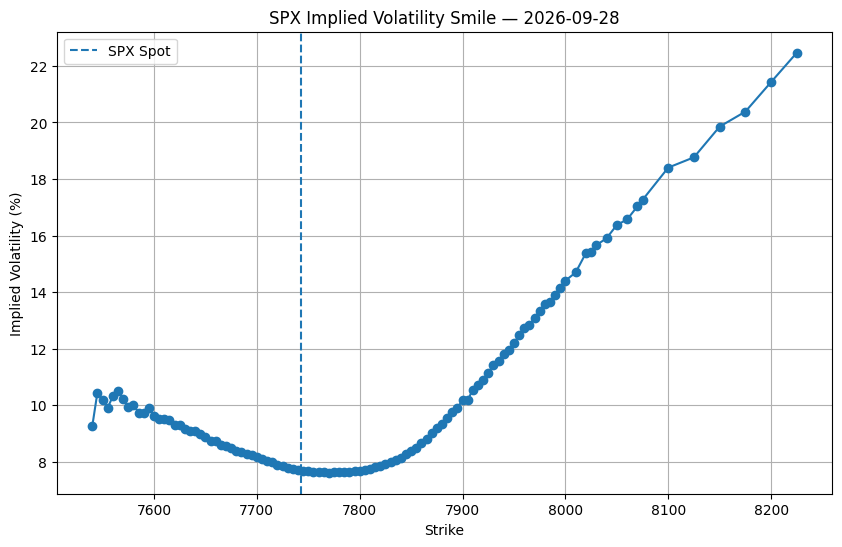

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    calls_iv["strike"],
    calls_iv["implied_vol"] * 100,
    marker="o"
)

plt.axvline(
    S0,
    linestyle="--",
    label="SPX Spot"
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title(f"SPX Implied Volatility Smile — {expiration}")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
calls_iv[
    [
        "strike",
        "bid",
        "ask",
        "mid_price",
        "volume",
        "openInterest",
        "implied_vol"
    ]
].sort_values("implied_vol", ascending=False).head(10)

,strike,bid,ask,mid_price,volume,openInterest,implied_vol
158,8225.0,0.05,0.10,0.075,339.0,111,0.224659
157,8200.0,0.05,0.10,0.075,100.0,164,0.214283
156,8175.0,0.05,0.10,0.075,262.0,331,0.203830
155,8150.0,0.05,0.15,0.100,325.0,94,0.198530
154,8125.0,0.05,0.15,0.100,731.0,331,0.187673
153,8100.0,0.10,0.20,0.150,81.0,425,0.184020
152,8075.0,0.10,0.20,0.150,113.0,526,0.172596
151,8070.0,0.10,0.20,0.150,67.0,51,0.170298
150,8060.0,0.10,0.20,0.150,65.0,97,0.165688
149,8050.0,0.10,0.25,0.175,2040.0,1788,0.163734


In [ ]:
calls_liquid = calls_iv
calls_liquid["spread"] = (
    calls_liquid["ask"] - calls_liquid["bid"]
)

calls_liquid["spread_pct"] = (
    calls_liquid["spread"] /
    calls_liquid["mid_price"]
) * 100

calls_liquid.head()

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,mid_price,implied_vol,implied_vol_pct,spread,spread_pct
51,SPXW260928C07540000,2026-09-25 16:55:10+00:00,7540.0,199.49,204.9,206.9,30.090012,17.762700,22.0,42,0.232857,True,REGULAR,USD,205.90,0.092538,9.253846,2.0,0.971345
52,SPXW260928C07545000,2026-09-25 16:48:43+00:00,7545.0,191.40,199.9,202.0,32.399994,20.377354,3.0,19,0.229744,True,REGULAR,USD,200.95,0.104449,10.444892,2.1,1.045036
53,SPXW260928C07550000,2026-09-25 19:42:42+00:00,7550.0,191.68,194.9,197.0,29.559998,18.233406,24.0,68,0.225136,True,REGULAR,USD,195.95,0.101790,10.178955,2.1,1.071702
54,SPXW260928C07555000,2026-09-25 19:04:55+00:00,7555.0,182.58,189.9,192.0,80.810005,79.404540,5.0,10,0.220528,True,REGULAR,USD,190.95,0.099132,9.913189,2.1,1.099764
55,SPXW260928C07560000,2026-09-25 15:44:27+00:00,7560.0,149.47,185.0,187.0,32.000000,27.240997,5.0,22,0.215920,True,REGULAR,USD,186.00,0.103101,10.310133,2.0,1.075269


In [ ]:
calls_liquid[[
    "strike",
    "bid",
    "ask",
    "mid_price",
    "spread_pct",
    "openInterest",
    "volume",
    "implied_vol"
]].sort_values(
    "spread_pct",
    ascending=False
).head(10)

,strike,bid,ask,mid_price,spread_pct,openInterest,volume,implied_vol
154,8125.0,0.05,0.15,0.100,100.000000,331,731.0,0.187673
155,8150.0,0.05,0.15,0.100,100.000000,94,325.0,0.198530
148,8040.0,0.10,0.25,0.175,85.714286,90,1651.0,0.159024
149,8050.0,0.10,0.25,0.175,85.714286,1788,2040.0,0.163734
142,7995.0,0.15,0.30,0.225,66.666667,43,3488.0,0.141571
140,7985.0,0.15,0.30,0.225,66.666667,101,150.0,0.136626
141,7990.0,0.15,0.30,0.225,66.666667,46,194.0,0.139102
143,8000.0,0.15,0.30,0.225,66.666667,1650,6431.0,0.144034
158,8225.0,0.05,0.10,0.075,66.666667,111,339.0,0.224659
157,8200.0,0.05,0.10,0.075,66.666667,164,100.0,0.214283


In [ ]:
calls_filtered = calls_liquid[
    calls_liquid["spread_pct"] <= 20
].copy()

In [ ]:
print("Before spread filter:", len(calls_liquid))
print("After spread filter:", len(calls_filtered))

Before spread filter: 108
After spread filter: 64


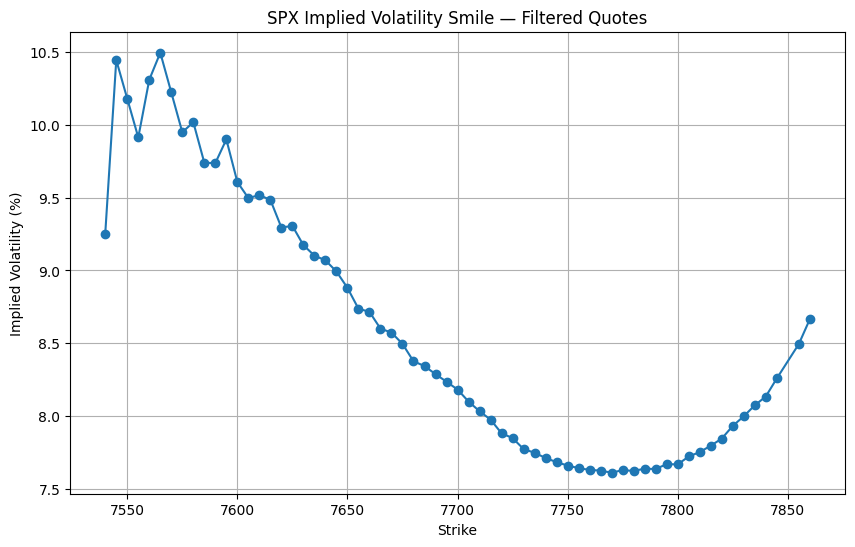

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    calls_filtered["strike"],
    calls_filtered["implied_vol"] * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title("SPX Implied Volatility Smile — Filtered Quotes")
plt.grid(True)

plt.show()

In [ ]:
print("Before:")
print(
    calls_liquid["strike"].min(),
    calls_liquid["strike"].max()
)

print("\nAfter:")
print(
    calls_filtered["strike"].min(),
    calls_filtered["strike"].max()
)

Before:
7540.0 8225.0

After:
7540.0 7860.0


In [ ]:
print(
    calls_filtered[
        ["strike", "bid", "ask", "mid_price", "spread_pct"]
    ].head()
)

print(
    calls_filtered[
        ["strike", "bid", "ask", "mid_price", "spread_pct"]
    ].tail()
)

    strike    bid    ask  mid_price  spread_pct
51  7540.0  204.9  206.9     205.90    0.971345
52  7545.0  199.9  202.0     200.95    1.045036
53  7550.0  194.9  197.0     195.95    1.071702
54  7555.0  189.9  192.0     190.95    1.099764
55  7560.0  185.0  187.0     186.00    1.075269
     strike   bid   ask  mid_price  spread_pct
110  7835.0  1.35  1.55      1.450   13.793103
111  7840.0  1.15  1.30      1.225   12.244898
112  7845.0  1.00  1.15      1.075   13.953488
114  7855.0  0.75  0.90      0.825   18.181818
115  7860.0  0.70  0.80      0.750   13.333333


In [ ]:
calls_filtered["moneyness"] = (
    calls_filtered["strike"] / S0
)

calls_filtered[[
    "strike",
    "moneyness",
    "implied_vol"
]].head()

,strike,moneyness,implied_vol
51,7540.0,0.973731,0.092538
52,7545.0,0.974377,0.104449
53,7550.0,0.975023,0.101790
54,7555.0,0.975668,0.099132
55,7560.0,0.976314,0.103101


In [ ]:
id="e7r1qk"
for i, exp in enumerate(expirations):
    print(i, exp)

0 2026-09-28
1 2026-09-29
2 2026-09-30
3 2026-10-01
4 2026-10-02
5 2026-10-05
6 2026-10-06
7 2026-10-07
8 2026-10-08
9 2026-10-09
10 2026-10-12
11 2026-10-13
12 2026-10-14
13 2026-10-15
14 2026-10-16
15 2026-10-19
16 2026-10-20
17 2026-10-21
18 2026-10-22
19 2026-10-23
20 2026-10-26
21 2026-10-27
22 2026-10-28
23 2026-10-29
24 2026-10-30
25 2026-11-03
26 2026-11-04
27 2026-11-06
28 2026-11-20
29 2026-11-30
30 2026-12-18
31 2026-12-31
32 2027-01-15
33 2027-01-29
34 2027-02-19
35 2027-02-26
36 2027-03-19
37 2027-03-31
38 2027-04-16
39 2027-05-21
40 2027-06-17
41 2027-06-30
42 2027-07-16
43 2027-08-20
44 2027-09-17
45 2027-09-30
46 2027-10-15
47 2027-12-17
48 2028-01-21
49 2028-06-16
50 2028-12-15
51 2029-12-21
52 2030-12-20
53 2031-12-19


In [ ]:
target_days = np.array([
    30,
    60,
    90,
    180,
    365
])

valuation_date = pd.to_datetime(
    spx.history(period="1d").index[-1]
).date()

expiration_dates = pd.to_datetime(
    expirations
).date

selected_expirations = []

for target in target_days:
    differences = np.array([
        abs((exp_date - valuation_date).days - target)
        for exp_date in expiration_dates
    ])

    selected_expirations.append(
        expirations[np.argmin(differences)]
    )

for target, exp in zip(target_days, selected_expirations):
    print(f"Target: {target:3d} days → Expiry: {exp}")

Target:  30 days → Expiry: 2026-10-26
Target:  60 days → Expiry: 2026-11-20
Target:  90 days → Expiry: 2026-12-18
Target: 180 days → Expiry: 2027-03-19
Target: 365 days → Expiry: 2027-09-30


In [ ]:
def build_iv_smile(expiration, S0, r):

    # Get option chain
    option_chain = spx.option_chain(expiration)
    calls = option_chain.calls.copy()

    # Calculate time to maturity
    valuation_date = pd.to_datetime(
        spx.history(period="1d").index[-1]
    ).date()

    expiration_date = pd.to_datetime(expiration).date()

    days_to_expiry = (
        expiration_date - valuation_date
    ).days

    T = days_to_expiry / 365

    # Mid price
    calls["mid_price"] = (
        calls["bid"] + calls["ask"]
    ) / 2

    # Basic quote filter
    calls_clean = calls[
        (calls["bid"] > 0) &
        (calls["ask"] > 0) &
        (calls["ask"] >= calls["bid"])
    ].copy()

    # Strike range around spot
    calls_clean = calls_clean[
        (calls_clean["strike"] >= 0.90 * S0) &
        (calls_clean["strike"] <= 1.10 * S0)
    ].copy()

    # Open interest filter
    calls_clean = calls_clean[
        calls_clean["openInterest"] > 0
    ].copy()

    # Bid-ask spread filter
    calls_clean["spread"] = (
        calls_clean["ask"] -
        calls_clean["bid"]
    )

    calls_clean["spread_pct"] = (
        calls_clean["spread"] /
        calls_clean["mid_price"]
    ) * 100

    calls_clean = calls_clean[
        calls_clean["spread_pct"] <= 20
    ].copy()

    # Calculate implied volatility
    calls_clean["implied_vol"] = calls_clean.apply(
        lambda row: implied_volatility(
            market_price=row["mid_price"],
            S0=S0,
            K=row["strike"],
            r=r,
            T=T,
            option_type="call"
        ),
        axis=1
    )

    # Remove failed IV inversions
    calls_clean = calls_clean.dropna(
        subset=["implied_vol"]
    ).copy()

    # Sort by strike
    calls_clean = calls_clean.sort_values(
        "strike"
    )

    return calls_clean, T

Expiration: 2026-10-26
T: 0.08493150684931507
Number of IV points: 31


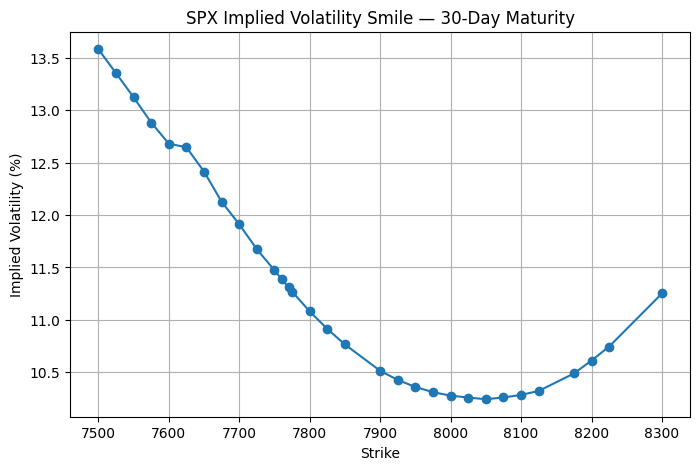

In [ ]:
calls_30d, T_30d = build_iv_smile(
    selected_expirations[0],
    S0,
    r
)

print("Expiration:", selected_expirations[0])
print("T:", T_30d)
print("Number of IV points:", len(calls_30d))
plt.figure(figsize=(8,5))

plt.plot(
    calls_30d["strike"],
    calls_30d["implied_vol"] * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title("SPX Implied Volatility Smile — 30-Day Maturity")
plt.grid(True)

plt.show()

In [ ]:
smiles = {}

for target, expiration in zip(target_days, selected_expirations):

    smile, T = build_iv_smile(
        expiration,
        S0,
        r
    )

    smiles[target] = {
        "expiration": expiration,
        "T": T,
        "data": smile
    }

    print(
        f"{target:3d} days → "
        f"{expiration} | "
        f"T = {T:.4f} | "
        f"IV points = {len(smile)}"
    )

 30 days → 2026-10-26 | T = 0.0849 | IV points = 31
 60 days → 2026-11-20 | T = 0.1534 | IV points = 236
 90 days → 2026-12-18 | T = 0.2301 | IV points = 196
180 days → 2027-03-19 | T = 0.4795 | IV points = 62
365 days → 2027-09-30 | T = 1.0137 | IV points = 25


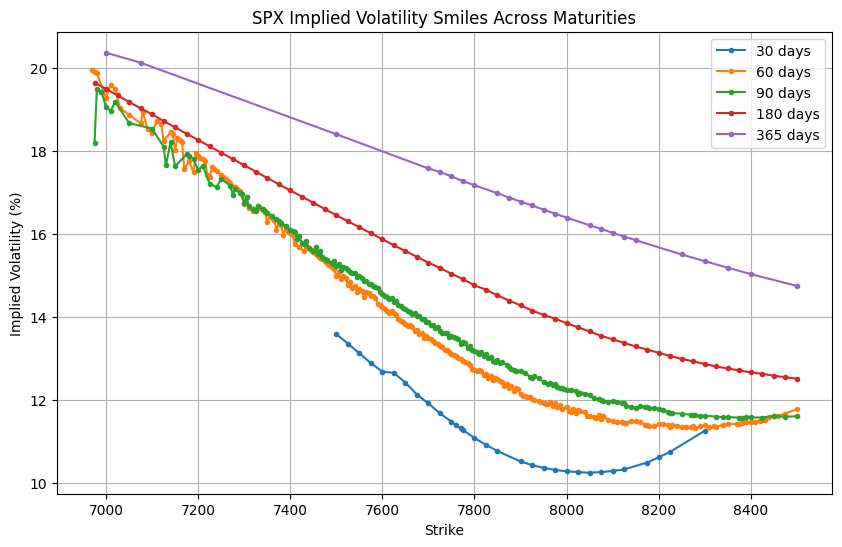

In [ ]:
plt.figure(figsize=(10, 6))

for target in target_days:

    data = smiles[target]["data"]

    plt.plot(
        data["strike"],
        data["implied_vol"] * 100,
        marker="o",
        markersize=3,
        label=f"{target} days"
    )

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title("SPX Implied Volatility Smiles Across Maturities")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
surface_data = []

for target in target_days:

    data = smiles[target]["data"].copy()

    data["target_days"] = target
    data["T"] = smiles[target]["T"]
    data["expiration"] = smiles[target]["expiration"]

    surface_data.append(
        data[
            [
                "expiration",
                "T",
                "target_days",
                "strike",
                "implied_vol"
            ]
        ]
    )

surface_df = pd.concat(
    surface_data,
    ignore_index=True
)

surface_df = surface_df.sort_values(
    ["T", "strike"]
).reset_index(drop=True)

print(surface_df.head(10))
print()
print("Total IV observations:", len(surface_df))

   expiration         T  target_days  strike  implied_vol
0  2026-10-26  0.084932           30  7500.0     0.135836
1  2026-10-26  0.084932           30  7525.0     0.133561
2  2026-10-26  0.084932           30  7550.0     0.131248
3  2026-10-26  0.084932           30  7575.0     0.128839
4  2026-10-26  0.084932           30  7600.0     0.126819
5  2026-10-26  0.084932           30  7625.0     0.126473
6  2026-10-26  0.084932           30  7650.0     0.124156
7  2026-10-26  0.084932           30  7675.0     0.121270
8  2026-10-26  0.084932           30  7700.0     0.119121
9  2026-10-26  0.084932           30  7725.0     0.116737

Total IV observations: 550


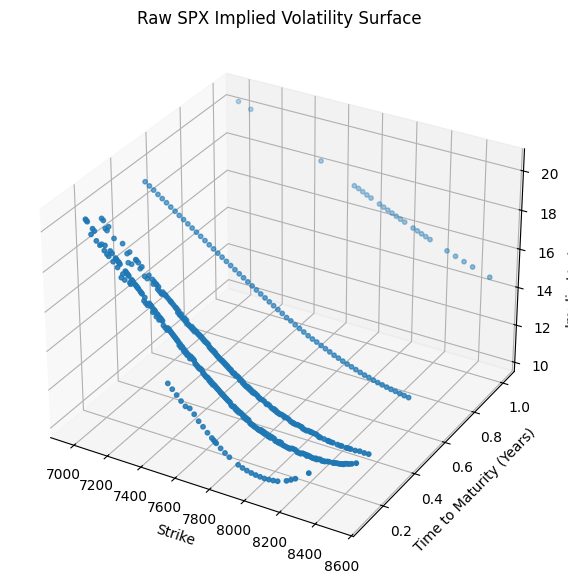

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    surface_df["strike"],
    surface_df["T"],
    surface_df["implied_vol"] * 100,
    s=10
)

ax.set_xlabel("Strike")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")

ax.set_title("Raw SPX Implied Volatility Surface")

plt.show()

In [ ]:
for target in target_days:

    data = smiles[target]["data"]

    print(
        f"{target:3d} days: "
        f"K = {data['strike'].min():.0f} "
        f"to {data['strike'].max():.0f} "
        f"| points = {len(data)}"
    )

 30 days: K = 7500 to 8300 | points = 31
 60 days: K = 6970 to 8500 | points = 236
 90 days: K = 6975 to 8500 | points = 196
180 days: K = 6975 to 8500 | points = 62
365 days: K = 7000 to 8500 | points = 25


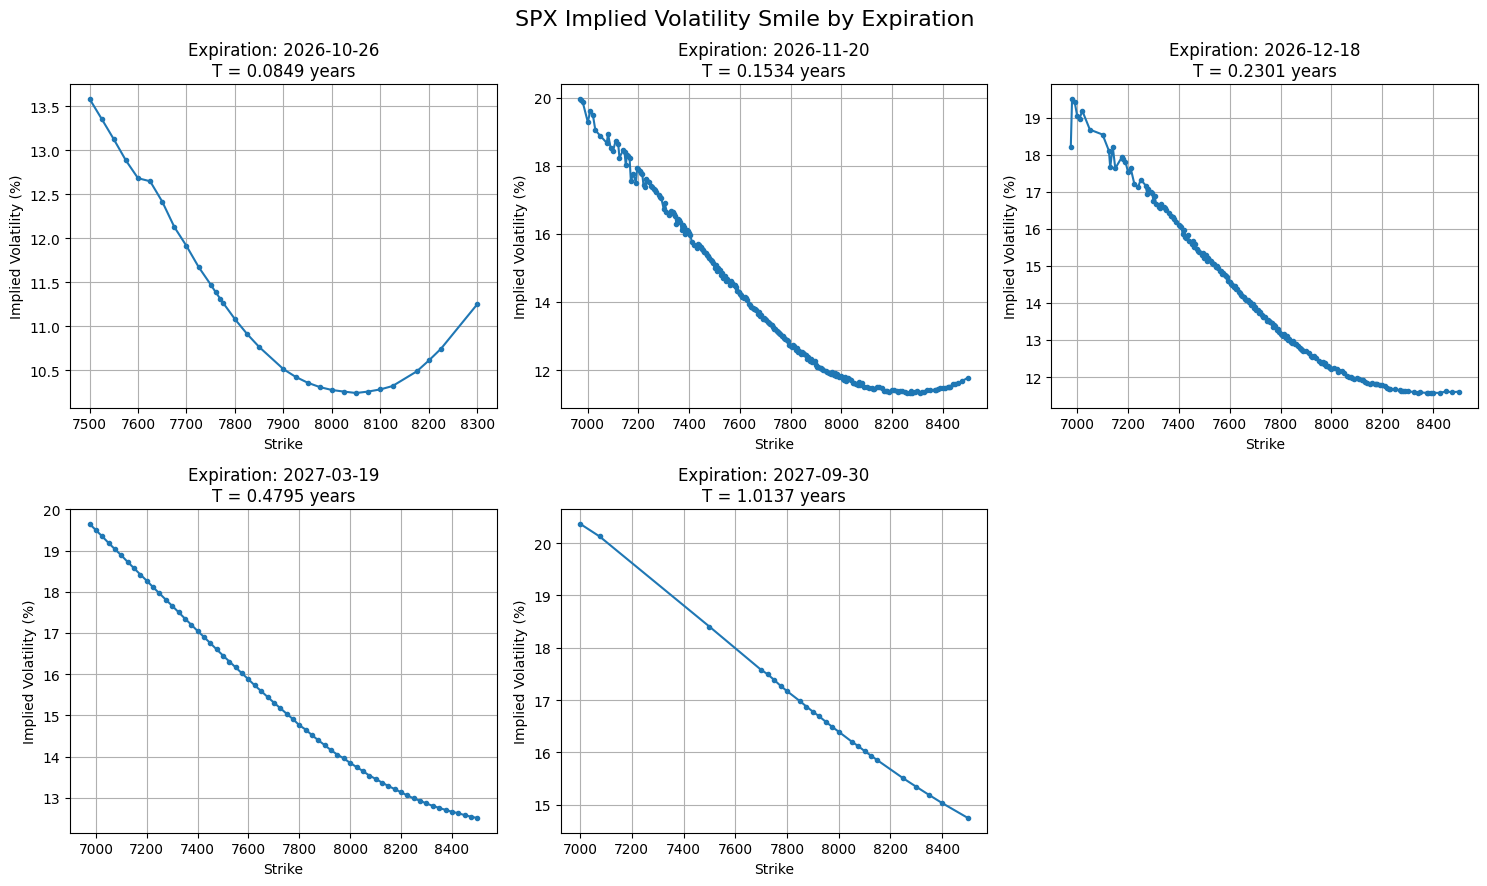

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, target in enumerate(target_days):

    data = smiles[target]["data"]
    expiration = smiles[target]["expiration"]
    T = smiles[target]["T"]

    axes[i].plot(
        data["strike"],
        data["implied_vol"] * 100,
        marker="o",
        markersize=3
    )

    axes[i].set_title(
        f"Expiration: {expiration}\n"
        f"T = {T:.4f} years"
    )

    axes[i].set_xlabel("Strike")
    axes[i].set_ylabel("Implied Volatility (%)")
    axes[i].grid(True)

# Remove the unused 6th subplot
fig.delaxes(axes[5])

fig.suptitle(
    "SPX Implied Volatility Smile by Expiration",
    fontsize=16
)

plt.tight_layout()
plt.show()

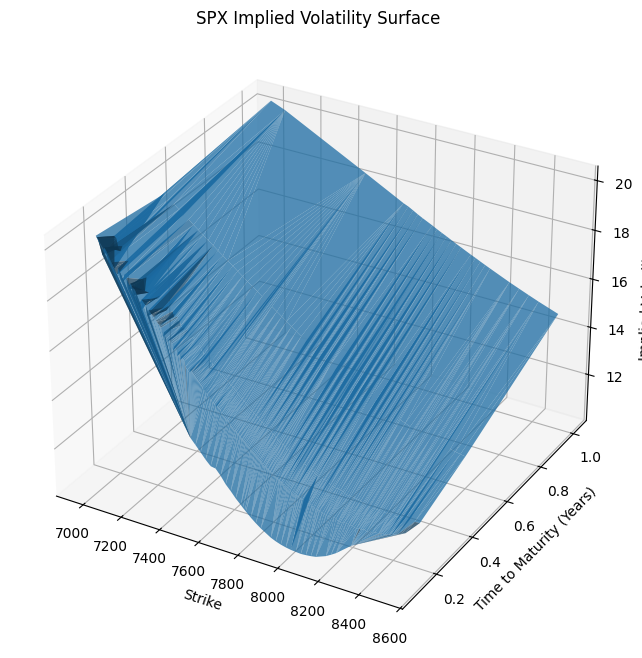

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    surface_df["strike"],
    surface_df["T"],
    surface_df["implied_vol"] * 100,
    alpha=0.75
)

ax.set_xlabel("Strike")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")

ax.set_title("SPX Implied Volatility Surface")

plt.show()

In [ ]:
def build_iv_smile(expiration, S0, r, valuation_date):

    # Get option chain
    option_chain = spx.option_chain(expiration)
    calls = option_chain.calls.copy()

    # Time to maturity
    expiration_date = pd.to_datetime(expiration).date()

    days_to_expiry = (
        expiration_date - valuation_date
    ).days

    T = days_to_expiry / 365

    # Skip expired / zero-maturity options
    if T <= 0:
        return pd.DataFrame(), T

    # Mid price
    calls["mid_price"] = (
        calls["bid"] + calls["ask"]
    ) / 2

    # Basic quote filter
    calls_clean = calls[
        (calls["bid"] > 0) &
        (calls["ask"] > 0) &
        (calls["ask"] >= calls["bid"])
    ].copy()

    # Strike range around spot
    calls_clean = calls_clean[
        (calls_clean["strike"] >= 0.90 * S0) &
        (calls_clean["strike"] <= 1.10 * S0)
    ].copy()

    # Open interest filter
    calls_clean = calls_clean[
        calls_clean["openInterest"] > 0
    ].copy()

    # Bid-ask spread filter
    calls_clean["spread"] = (
        calls_clean["ask"] -
        calls_clean["bid"]
    )

    calls_clean["spread_pct"] = (
        calls_clean["spread"] /
        calls_clean["mid_price"]
    ) * 100

    calls_clean = calls_clean[
        calls_clean["spread_pct"] <= 20
    ].copy()

    # Implied volatility
    calls_clean["implied_vol"] = calls_clean.apply(
        lambda row: implied_volatility(
            market_price=row["mid_price"],
            S0=S0,
            K=row["strike"],
            r=r,
            T=T,
            option_type="call"
        ),
        axis=1
    )

    # Remove failed inversions
    calls_clean = calls_clean.dropna(
        subset=["implied_vol"]
    ).copy()

    # Sort by strike
    calls_clean = calls_clean.sort_values(
        "strike"
    )

    return calls_clean, T

In [ ]:
valuation_date = pd.to_datetime(
    spx.history(period="1d").index[-1]
).date()

print("Valuation date:", valuation_date)
print("Number of expirations:", len(expirations))

Valuation date: 2026-09-25
Number of expirations: 54


In [ ]:
all_smiles = {}

for i, expiration in enumerate(expirations):

    smile, T = build_iv_smile(
        expiration,
        S0,
        r,
        valuation_date
    )

    all_smiles[expiration] = {
        "T": T,
        "data": smile
    }

    print(
        f"{i+1:2d}/{len(expirations)} | "
        f"{expiration} | "
        f"T = {T:.4f} | "
        f"IV points = {len(smile)}"
    )

 1/54 | 2026-09-28 | T = 0.0082 | IV points = 64
 2/54 | 2026-09-29 | T = 0.0110 | IV points = 66
 3/54 | 2026-09-30 | T = 0.0137 | IV points = 86
 4/54 | 2026-10-01 | T = 0.0164 | IV points = 84
 5/54 | 2026-10-02 | T = 0.0192 | IV points = 111
 6/54 | 2026-10-05 | T = 0.0274 | IV points = 96
 7/54 | 2026-10-06 | T = 0.0301 | IV points = 85
 8/54 | 2026-10-07 | T = 0.0329 | IV points = 87
 9/54 | 2026-10-08 | T = 0.0356 | IV points = 85
10/54 | 2026-10-09 | T = 0.0384 | IV points = 128
11/54 | 2026-10-12 | T = 0.0466 | IV points = 78
12/54 | 2026-10-13 | T = 0.0493 | IV points = 62
13/54 | 2026-10-14 | T = 0.0521 | IV points = 67
14/54 | 2026-10-15 | T = 0.0548 | IV points = 70
15/54 | 2026-10-16 | T = 0.0575 | IV points = 213
16/54 | 2026-10-19 | T = 0.0658 | IV points = 63
17/54 | 2026-10-20 | T = 0.0685 | IV points = 58
18/54 | 2026-10-21 | T = 0.0712 | IV points = 52
19/54 | 2026-10-22 | T = 0.0740 | IV points = 46
20/54 | 2026-10-23 | T = 0.0767 | IV points = 94
21/54 | 2026-10-2

In [ ]:
import matplotlib.dates as mdates

plot_data = []

for expiration, info in all_smiles.items():

    data = info["data"]

    if len(data) == 0:
        continue

    temp = data[
        ["strike", "implied_vol"]
    ].copy()

    temp["expiration"] = pd.to_datetime(expiration)

    plot_data.append(temp)

all_surface_points = pd.concat(
    plot_data,
    ignore_index=True
)

print("Total usable surface observations:",
      len(all_surface_points))

Total usable surface observations: 4291


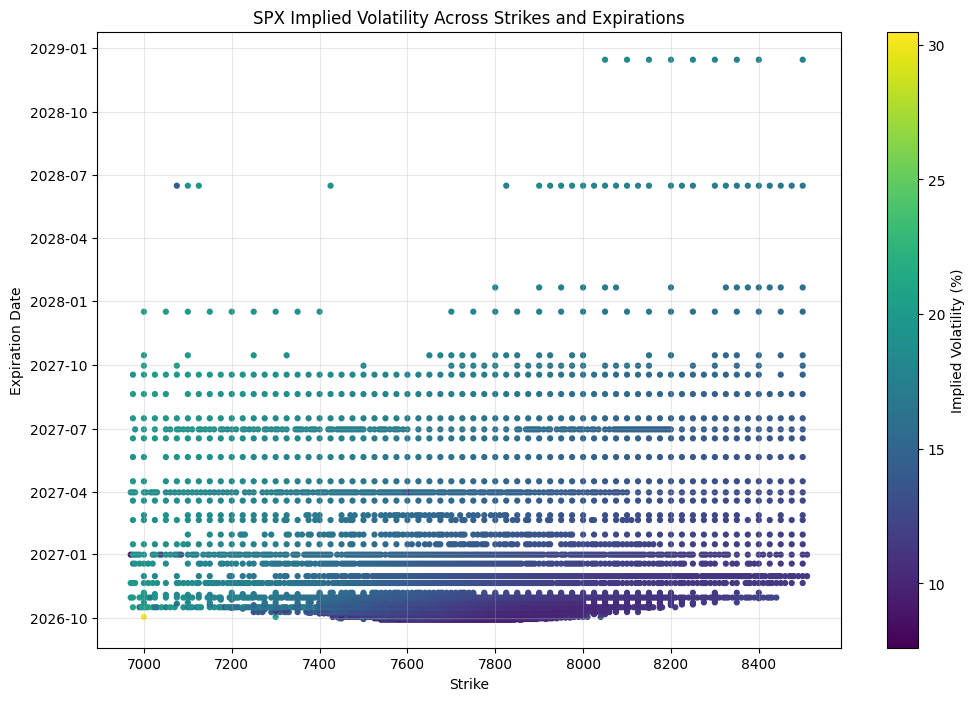

In [ ]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    all_surface_points["strike"],
    all_surface_points["expiration"],
    c=all_surface_points["implied_vol"] * 100,
    s=12
)

plt.xlabel("Strike")
plt.ylabel("Expiration Date")
plt.title("SPX Implied Volatility Across Strikes and Expirations")

plt.colorbar(
    scatter,
    label="Implied Volatility (%)"
)

plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
surface_points = []

for expiration, info in all_smiles.items():

    data = info["data"]

    if len(data) == 0:
        continue

    temp = data[
        ["strike", "implied_vol"]
    ].copy()

    temp["expiration"] = expiration
    temp["T"] = info["T"]

    surface_points.append(temp)

surface_points = pd.concat(
    surface_points,
    ignore_index=True
)

print(surface_points.head())
print("Total observations:", len(surface_points))

   strike  implied_vol  expiration         T
0  7540.0     0.092538  2026-09-28  0.008219
1  7545.0     0.104449  2026-09-28  0.008219
2  7550.0     0.101790  2026-09-28  0.008219
3  7555.0     0.099132  2026-09-28  0.008219
4  7560.0     0.103101  2026-09-28  0.008219
Total observations: 4291


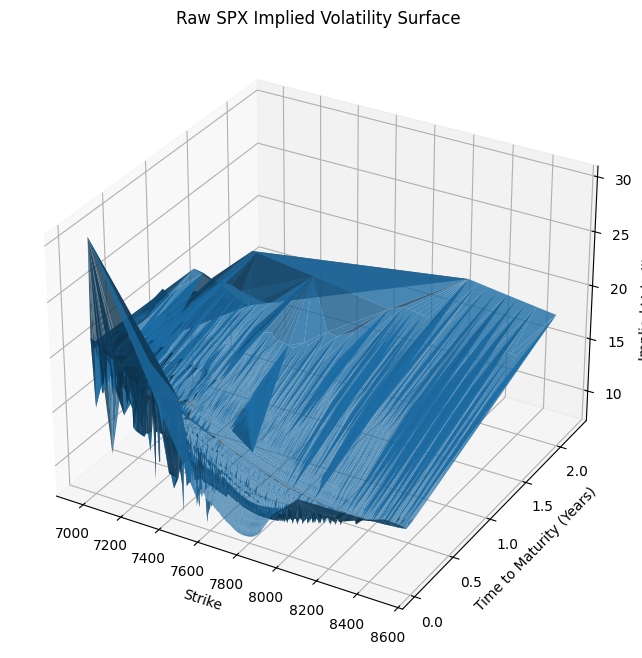

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    surface_points["strike"],
    surface_points["T"],
    surface_points["implied_vol"] * 100,
    alpha=0.8
)

ax.set_xlabel("Strike")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")

ax.set_title(
    "Raw SPX Implied Volatility Surface"
)

plt.show()

In [ ]:
expiration = "2026-11-20"

data = all_smiles[expiration]["data"]

K = data["strike"].values
IV = data["implied_vol"].values

In [ ]:
from scipy.interpolate import UnivariateSpline
spline = UnivariateSpline(
    K,
    IV,
    s=0.0005
)

K_smooth = np.linspace(
    K.min(),
    K.max(),
    300
)

IV_smooth = spline(K_smooth)

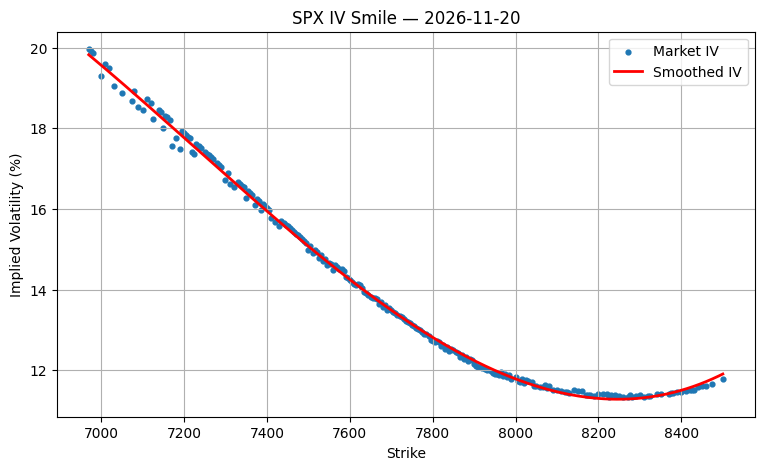

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    K,
    IV * 100,
    s=12,
    label="Market IV"
)

plt.plot(
    K_smooth,
    IV_smooth * 100,
    linewidth=2,
    label="Smoothed IV",
    color='r'
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")

plt.title(
    f"SPX IV Smile — {expiration}"
)

plt.legend()
plt.grid(True)

plt.show()

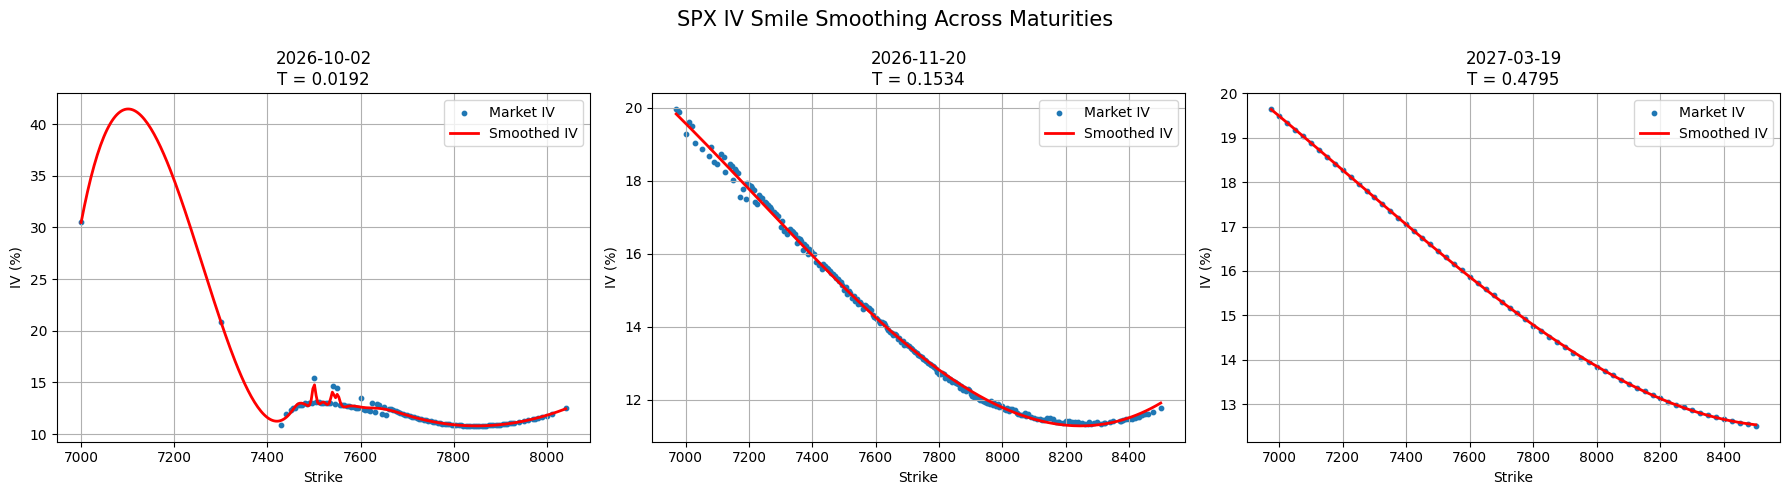

In [ ]:
test_expirations = [
    "2026-10-02",
    "2026-11-20",
    "2027-03-19"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, expiration in zip(axes, test_expirations):

    data = all_smiles[expiration]["data"]

    K = data["strike"].values
    IV = data["implied_vol"].values

    spline = UnivariateSpline(
        K,
        IV,
        s=0.0005
    )

    K_smooth = np.linspace(
        K.min(),
        K.max(),
        300
    )

    IV_smooth = spline(K_smooth)

    ax.scatter(
        K,
        IV * 100,
        s=10,
        label="Market IV"
    )

    ax.plot(
        K_smooth,
        IV_smooth * 100,
        linewidth=2,
        label="Smoothed IV",
        color='r'
    )

    ax.set_title(
        f"{expiration}\n"
        f"T = {all_smiles[expiration]['T']:.4f}"
    )

    ax.set_xlabel("Strike")
    ax.set_ylabel("IV (%)")
    ax.grid(True)
    ax.legend()

plt.suptitle(
    "SPX IV Smile Smoothing Across Maturities",
    fontsize=15
)

plt.tight_layout()
plt.show()

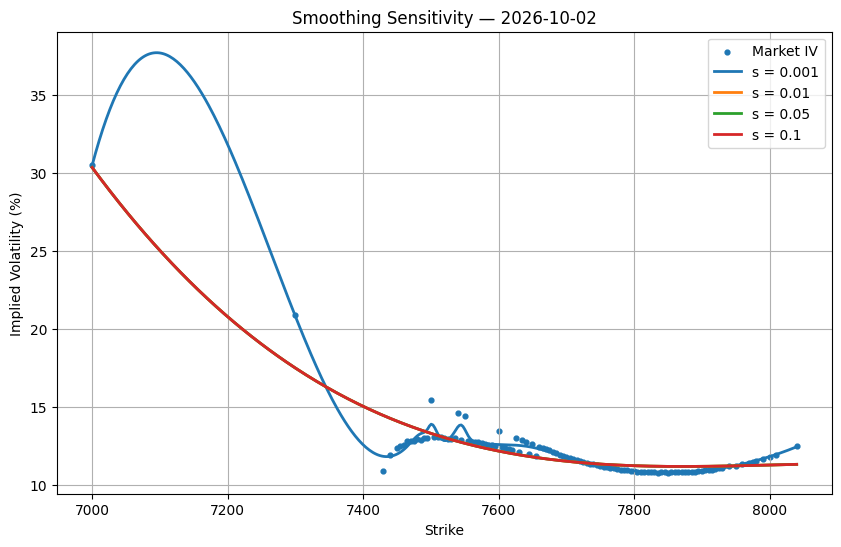

In [ ]:
expiration = "2026-10-02"

data = all_smiles[expiration]["data"]

K = data["strike"].values
IV = data["implied_vol"].values

s_values = [
    0.001,
    0.01,
    0.05,
    0.1
]

plt.figure(figsize=(10, 6))

plt.scatter(
    K,
    IV * 100,
    s=12,
    label="Market IV"
)

K_smooth = np.linspace(
    K.min(),
    K.max(),
    400
)

for s in s_values:

    spline = UnivariateSpline(
        K,
        IV,
        s=s
    )

    IV_smooth = spline(K_smooth)

    plt.plot(
        K_smooth,
        IV_smooth * 100,
        linewidth=2,
        label=f"s = {s}"
    )

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")

plt.title(
    "Smoothing Sensitivity — 2026-10-02"
)

plt.legend()
plt.grid(True)

plt.show()

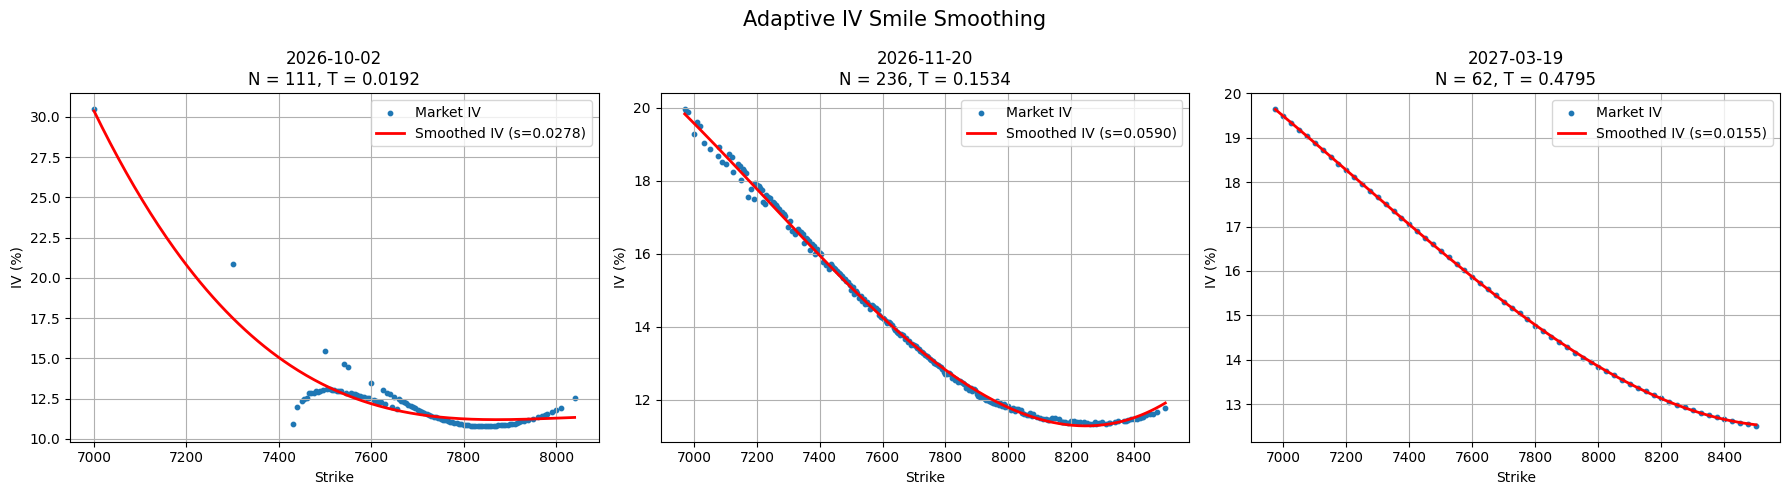

In [ ]:
alpha = 0.00025

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, expiration in zip(axes, test_expirations):

    data = all_smiles[expiration]["data"]

    K = data["strike"].values
    IV = data["implied_vol"].values

    N = len(K)

    # Adaptive smoothing parameter
    s = alpha * N

    spline = UnivariateSpline(
        K,
        IV,
        s=s
    )

    K_smooth = np.linspace(
        K.min(),
        K.max(),
        300
    )

    IV_smooth = spline(K_smooth)

    ax.scatter(
        K,
        IV * 100,
        s=10,
        label="Market IV"
    )

    ax.plot(
        K_smooth,
        IV_smooth * 100,
        linewidth=2,
        label=f"Smoothed IV (s={s:.4f})",
        color='r'
    )

    ax.set_title(
        f"{expiration}\n"
        f"N = {N}, T = {all_smiles[expiration]['T']:.4f}"
    )

    ax.set_xlabel("Strike")
    ax.set_ylabel("IV (%)")
    ax.grid(True)
    ax.legend()

plt.suptitle(
    "Adaptive IV Smile Smoothing",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.interpolate import PchipInterpolator

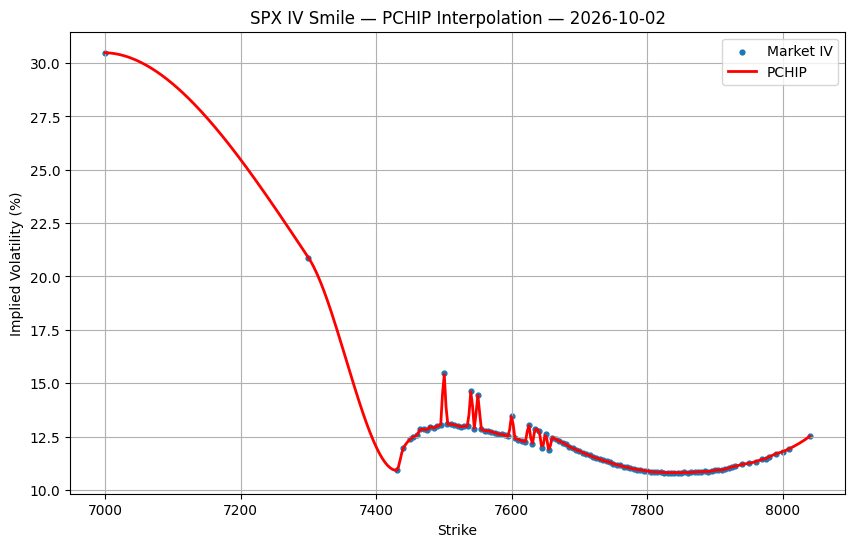

In [ ]:
expiration = "2026-10-02"

data = all_smiles[expiration]["data"]

K = data["strike"].values
IV = data["implied_vol"].values

# PCHIP interpolation
pchip = PchipInterpolator(
    K,
    IV
)

K_smooth = np.linspace(
    K.min(),
    K.max(),
    400
)

IV_smooth = pchip(K_smooth)

plt.figure(figsize=(10, 6))

plt.scatter(
    K,
    IV * 100,
    s=12,
    label="Market IV"
)

plt.plot(
    K_smooth,
    IV_smooth * 100,
    linewidth=2,
    label="PCHIP",
    color='r'
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")

plt.title(
    f"SPX IV Smile — PCHIP Interpolation — {expiration}"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
from statsmodels.nonparametric.smoothers_lowess import lowess
def plot_smooth_lowess(fr):
  expiration = "2026-10-02"

  data = all_smiles[expiration]["data"]

  K = data["strike"].values
  IV = data["implied_vol"].values

  # LOWESS smoothing
  smoothed = lowess(
      IV,
      K,
      frac=fr,
      it=2,
      return_sorted=True
  )

  K_smooth = smoothed[:, 0]
  IV_smooth = smoothed[:, 1]

  plt.figure(figsize=(10, 6))

  plt.scatter(
      K,
      IV * 100,
      s=12,
      label="Market IV"
  )

  plt.plot(
      K_smooth,
      IV_smooth * 100,
      linewidth=2,
      label="LOWESS"
  )

  plt.xlabel("Strike")
  plt.ylabel("Implied Volatility (%)")

  plt.title(
      f"SPX IV Smile — LOWESS Smoothing — {expiration}"
  )

  plt.legend()
  plt.grid(True)

  plt.show()


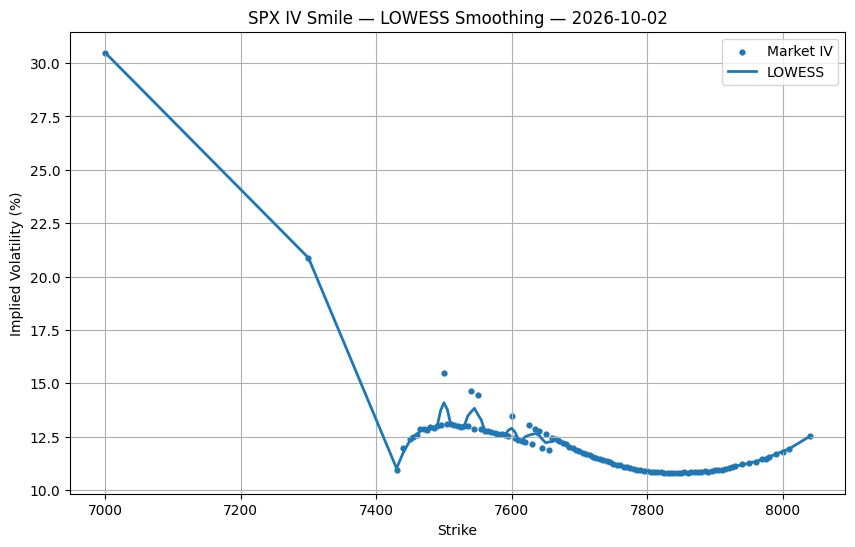

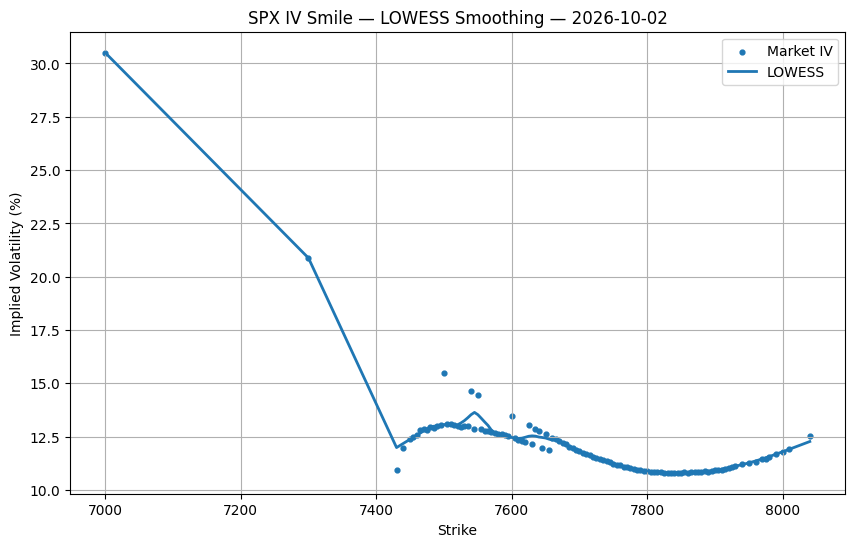

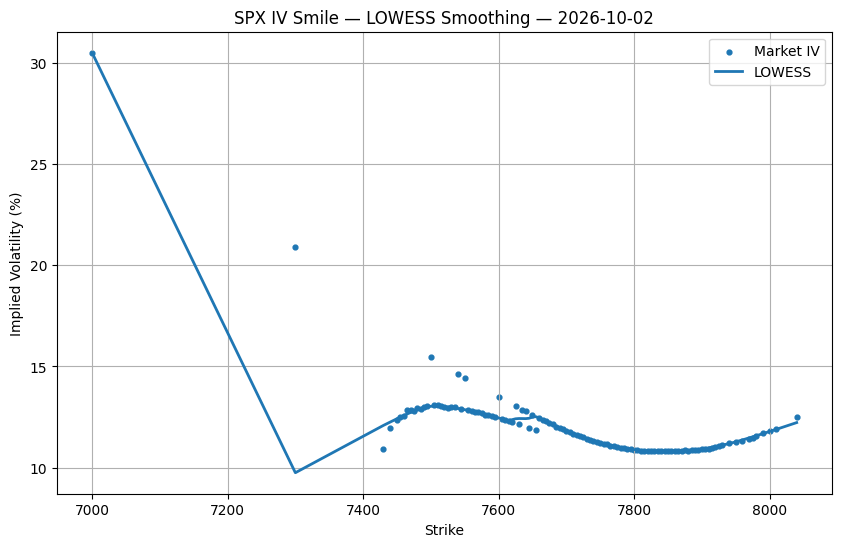

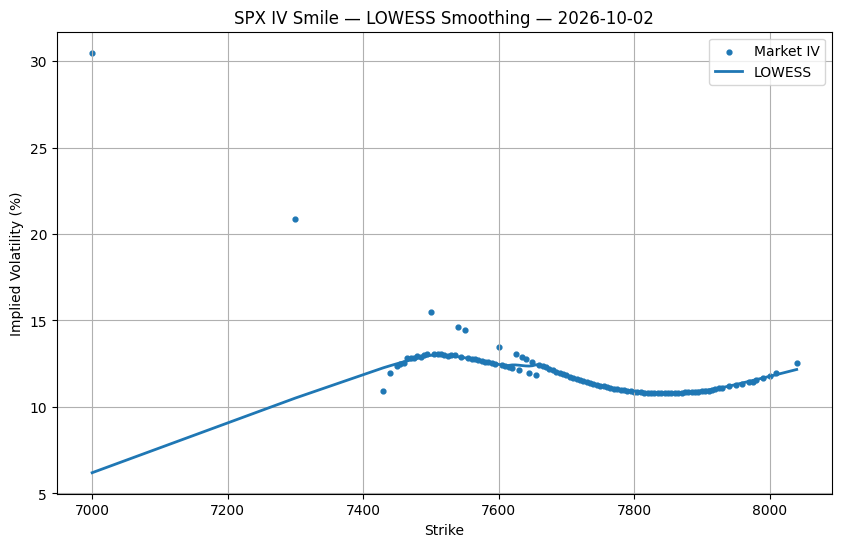

In [ ]:
frac_values = [0.05, 0.10, 0.15, 0.20]
for f in frac_values:
  plot_smooth_lowess(f)

In [ ]:
from statsmodels.nonparametric.smoothers_lowess import lowess

smoothed_smiles = {}

for expiration, smile_info in all_smiles.items():

    data = smile_info["data"].copy()
    T = smile_info["T"]

    # Skip expirations with too few observations
    if len(data) < 10:
        continue

    K = data["strike"].values
    IV = data["implied_vol"].values

    # LOWESS smoothing
    smoothed = lowess(
        IV,
        K,
        frac=0.10,
        it=2,
        return_sorted=True
    )

    smoothed_smiles[expiration] = {
        "T": T,
        "strike": smoothed[:, 0],
        "implied_vol": smoothed[:, 1]
    }

print(
    "Smoothed expirations:",
    len(smoothed_smiles)
)

Smoothed expirations: 50


In [ ]:
surface_data = []

for expiration, smile in smoothed_smiles.items():
    T = smile["T"]
    strikes = smile["strike"]
    IVs = smile["implied_vol"]

    for K, IV in zip(strikes, IVs):
        surface_data.append({
            "expiration": expiration,
            "T": T,
            "strike": K,
            "implied_vol": IV
        })

surface_df = pd.DataFrame(surface_data)

surface_df.head()

,expiration,T,strike,implied_vol
0,2026-09-28,0.008219,7540.0,0.100478
1,2026-09-28,0.008219,7545.0,0.101134
2,2026-09-28,0.008219,7550.0,0.101790
3,2026-09-28,0.008219,7555.0,0.102445
4,2026-09-28,0.008219,7560.0,0.102225


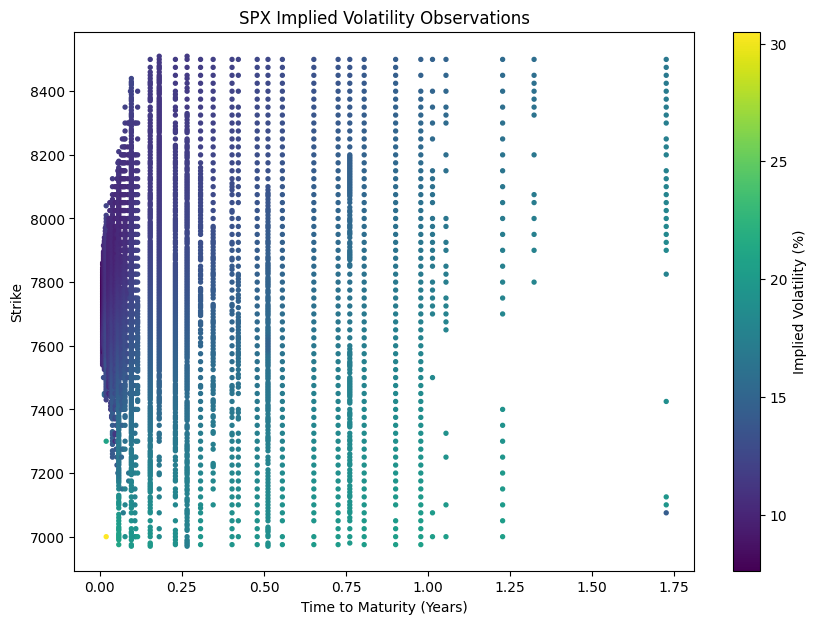

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    surface_df["T"],
    surface_df["strike"],
    c=surface_df["implied_vol"] * 100,
    s=8
)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Strike")
plt.title("SPX Implied Volatility Observations")
plt.colorbar(label="Implied Volatility (%)")

plt.show()

In [ ]:
from scipy.interpolate import griddata

K_grid = np.linspace(
    surface_df["strike"].min(),
    surface_df["strike"].max(),
    150
)

T_grid = np.linspace(
    surface_df["T"].min(),
    surface_df["T"].max(),
    100
)

K_mesh, T_mesh = np.meshgrid(K_grid, T_grid)

In [ ]:
IV_grid = griddata(
    points=(
        surface_df["strike"],
        surface_df["T"]
    ),
    values=surface_df["implied_vol"],
    xi=(K_mesh, T_mesh),
    method="linear"
)


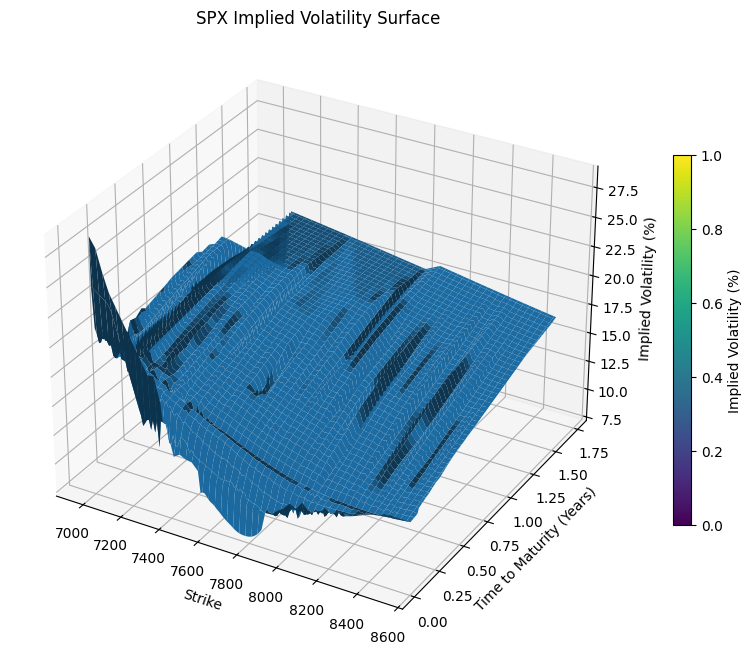

In [ ]:
fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    K_mesh,
    T_mesh,
    IV_grid * 100,
    edgecolor="none"
)

ax.set_xlabel("Strike")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")

ax.set_title("SPX Implied Volatility Surface")

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Implied Volatility (%)"
)

plt.show()

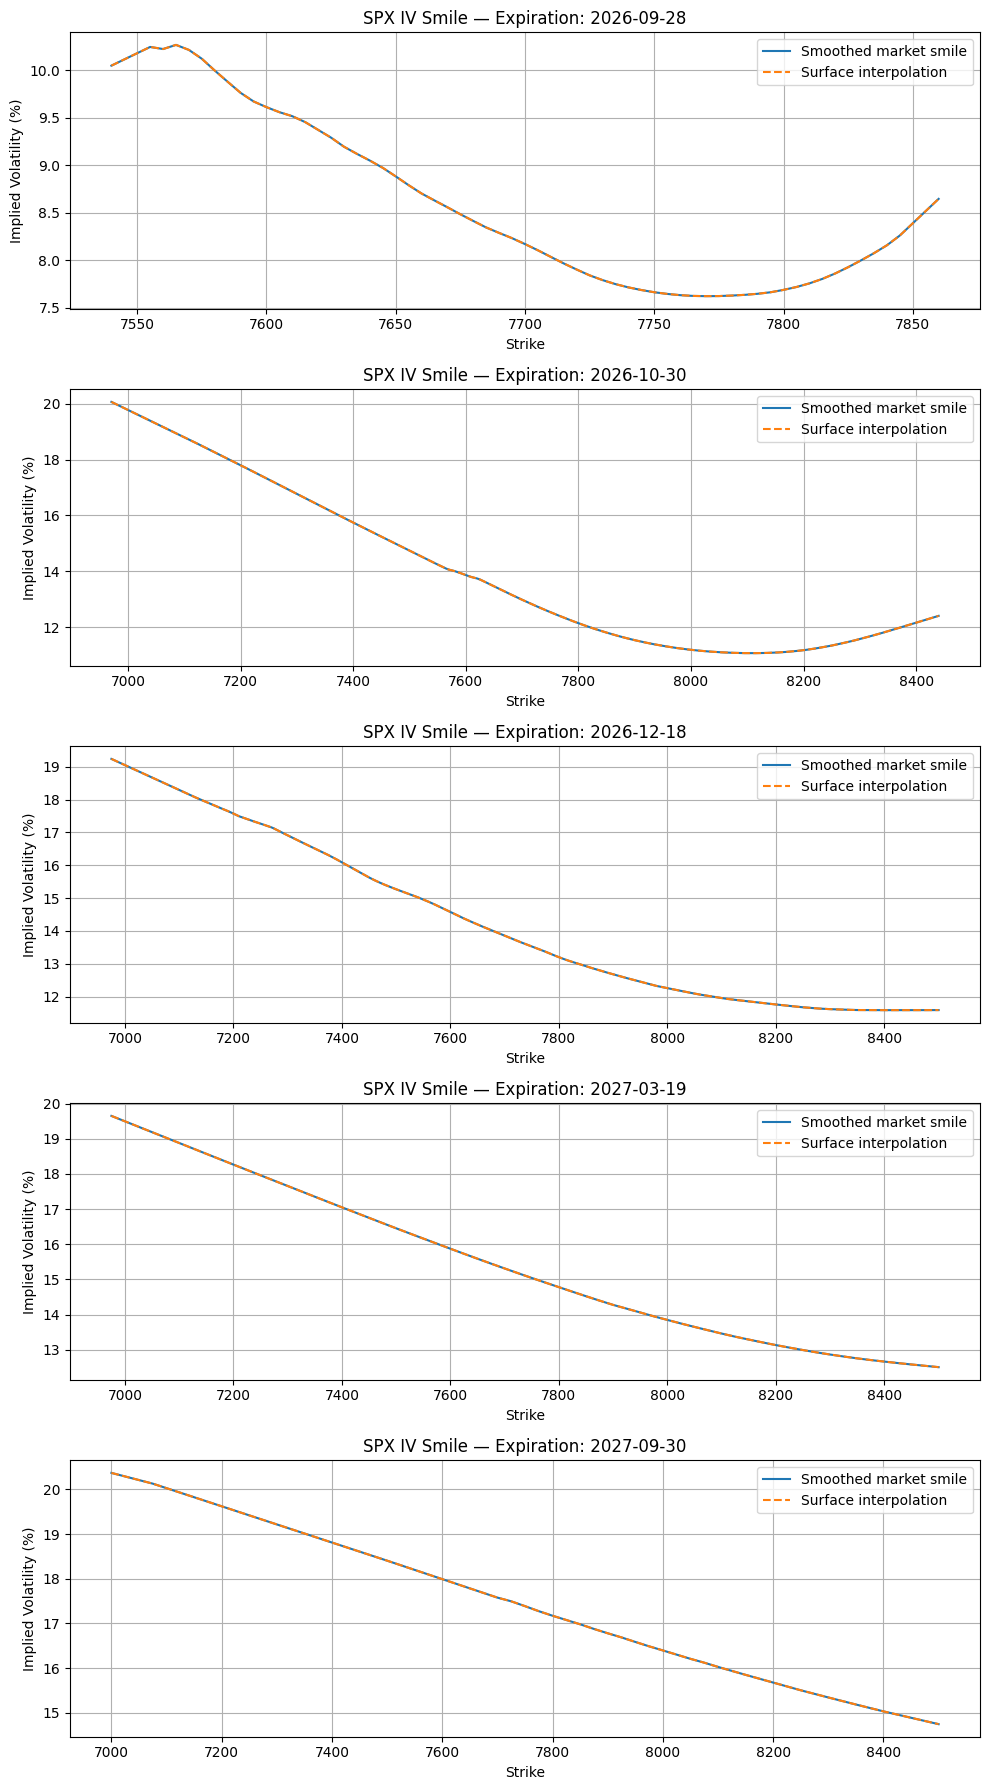

In [ ]:
from scipy.interpolate import griddata

# Choose a few representative maturities
selected_expirations = [
    "2026-09-28",
    "2026-10-30",
    "2026-12-18",
    "2027-03-19",
    "2027-09-30"
]

fig, axes = plt.subplots(
    len(selected_expirations),
    1,
    figsize=(10, 18)
)

for ax, expiration in zip(axes, selected_expirations):

    smile = smoothed_smiles[expiration]

    T = smile["T"]
    K_original = smile["strike"]
    IV_original = smile["implied_vol"]

    # Interpolated IV from the surface
    IV_surface = griddata(
        (surface_df["strike"], surface_df["T"]),
        surface_df["implied_vol"],
        (K_original, np.full_like(K_original, T)),
        method="linear"
    )

    # Plot original smoothed smile
    ax.plot(
        K_original,
        IV_original * 100,
        label="Smoothed market smile"
    )

    # Plot surface-implied smile
    ax.plot(
        K_original,
        IV_surface * 100,
        "--",
        label="Surface interpolation"
    )

    ax.set_title(
        f"SPX IV Smile — Expiration: {expiration}"
    )

    ax.set_xlabel("Strike")
    ax.set_ylabel("Implied Volatility (%)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
q = 0.00

surface_df["forward_price"] = (
    S0 * np.exp((r - q) * surface_df["T"])
)

surface_df["log_moneyness"] = np.log(
    surface_df["strike"] / surface_df["forward_price"]
)

surface_df[
    ["T", "strike", "forward_price", "log_moneyness", "implied_vol"]
].head(10)


,T,strike,forward_price,log_moneyness,implied_vol
0,0.008219,7540.0,7745.956353,-0.026949,0.100478
1,0.008219,7545.0,7745.956353,-0.026286,0.101134
2,0.008219,7550.0,7745.956353,-0.025623,0.101790
3,0.008219,7555.0,7745.956353,-0.024961,0.102445
4,0.008219,7560.0,7745.956353,-0.024300,0.102225
5,0.008219,7565.0,7745.956353,-0.023639,0.102661
6,0.008219,7570.0,7745.956353,-0.022978,0.102131
7,0.008219,7575.0,7745.956353,-0.022318,0.101199
8,0.008219,7580.0,7745.956353,-0.021658,0.099958
9,0.008219,7585.0,7745.956353,-0.020998,0.098777


In [ ]:
k_grid = np.linspace(
    surface_df["log_moneyness"].min(),
    surface_df["log_moneyness"].max(),
    150
)

T_grid = np.linspace(
    surface_df["T"].min(),
    surface_df["T"].max(),
    100
)

k_mesh, T_mesh = np.meshgrid(k_grid, T_grid)

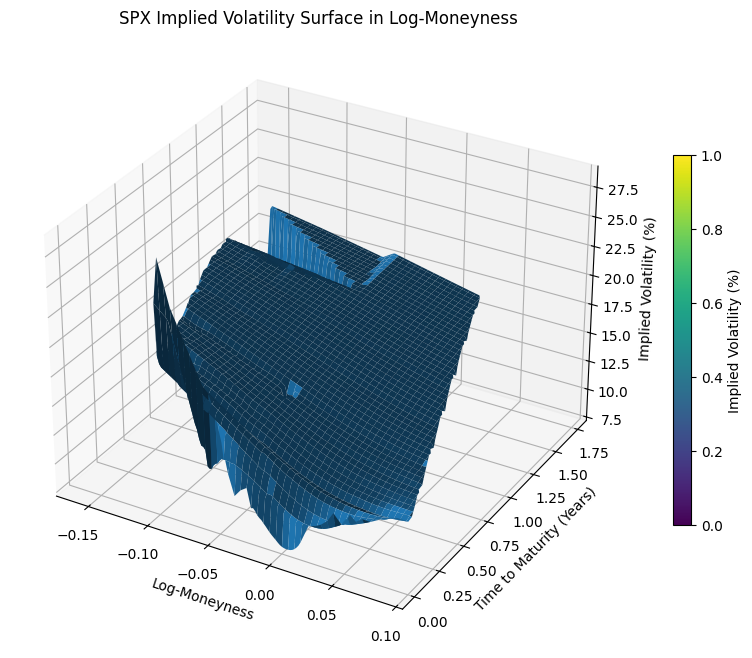

In [ ]:
from scipy.interpolate import griddata

IV_kT = griddata(
    (
        surface_df["log_moneyness"],
        surface_df["T"]
    ),
    surface_df["implied_vol"],
    (k_mesh, T_mesh),
    method="linear"
)

fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    k_mesh,
    T_mesh,
    IV_kT * 100,
    edgecolor="none"
)

ax.set_xlabel("Log-Moneyness")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")

ax.set_title(
    "SPX Implied Volatility Surface in Log-Moneyness"
)

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Implied Volatility (%)"
)

plt.show()

In [ ]:
forward_grid = S0 * np.exp((r - q) * T_mesh)

K_mesh = forward_grid * np.exp(k_mesh)

# Dupire Local Volatility

In [ ]:
C_kT = np.full_like(IV_kT, np.nan)

for i in range(T_mesh.shape[0]):
    for j in range(T_mesh.shape[1]):

        sigma = IV_kT[i, j]
        T = T_mesh[i, j]
        K = K_mesh[i, j]

        if np.isfinite(sigma) and T > 0:

            C_kT[i, j] = black_scholes_price(
                S0=S0,
                K=K,
                r=r,
                sigma=sigma,
                T=T,
                option_type="call"
            )


In [ ]:
d2C_dK2 = np.full_like(C_kT, np.nan)

for i in range(C_kT.shape[0]):

    dC_row = dC_dK[i, :]
    K_row = K_mesh[i, :]

    valid = np.isfinite(dC_row)

    if valid.sum() > 2:
        d2C_dK2[i, valid] = np.gradient(
            dC_row[valid],
            K_row[valid]
        )

In [ ]:
print("C_K range:", np.nanmin(dC_dK), np.nanmax(dC_dK))
print("C_KK range:", np.nanmin(d2C_dK2), np.nanmax(d2C_dK2))

C_K range: -1.4922108061592283 5.563123652545293
C_KK range: -0.2655261376040595 0.2641386059267007


In [ ]:
k_min = surface_df["log_moneyness"].min()
k_max = surface_df["log_moneyness"].max()

k_common = np.linspace(k_min, k_max, 150)

print(k_common.min(), k_common.max())

-0.15931583159485058 0.08716688663921313


In [ ]:
from scipy.interpolate import interp1d

smile_grid = []

for expiration, smile in smoothed_smiles.items():

    T = smile["T"]

    K = smile["strike"]
    IV = smile["implied_vol"]

    F = S0 * np.exp((r - q) * T)

    k = np.log(K / F)

    order = np.argsort(k)

    k = k[order]
    IV = IV[order]

    # Only interpolate inside the observed smile range
    k_low = max(k_common.min(), k.min())
    k_high = min(k_common.max(), k.max())

    mask = (
        (k_common >= k_low) &
        (k_common <= k_high)
    )

    if mask.sum() < 10:
        continue

    interpolator = interp1d(
        k,
        IV,
        kind="linear",
        bounds_error=False,
        fill_value=np.nan
    )

    IV_common = interpolator(k_common[mask])

    row = {
        "T": T,
        "IV": np.full(len(k_common), np.nan)
    }

    row["IV"][mask] = IV_common

    smile_grid.append(row)

In [ ]:
T_common = np.array([row["T"] for row in smile_grid])

IV_matrix = np.array([row["IV"] for row in smile_grid])

print("T shape:", T_common.shape)
print("IV matrix shape:", IV_matrix.shape)

T shape: (50,)
IV matrix shape: (50, 150)


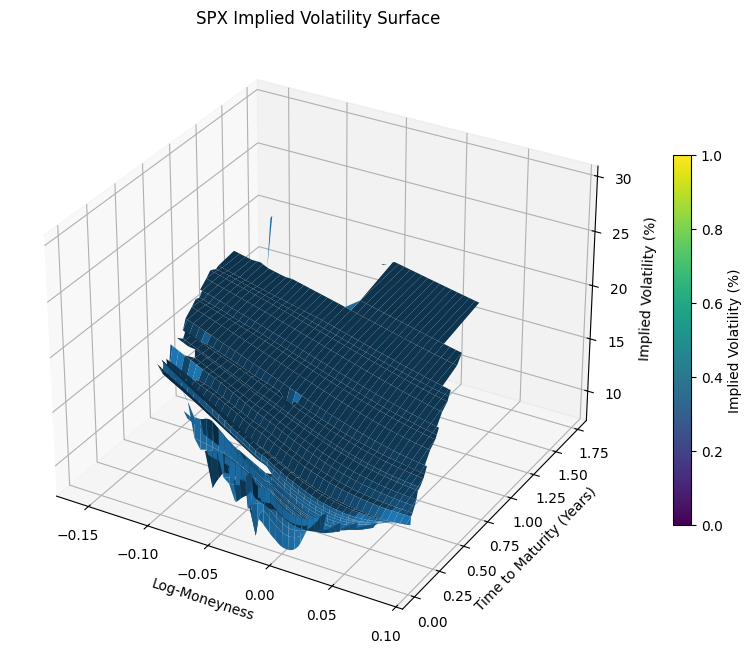

In [ ]:
k_mesh, T_mesh = np.meshgrid(
    k_common,
    T_common
)

fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    k_mesh,
    T_mesh,
    IV_matrix * 100,
    edgecolor="none"
)

ax.set_xlabel("Log-Moneyness")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")
ax.set_title("SPX Implied Volatility Surface")

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Implied Volatility (%)"
)

plt.show()

In [ ]:
order = np.argsort(T_common)

T_common = T_common[order]
IV_matrix = IV_matrix[order, :]

In [ ]:
T_regular = np.linspace(
    T_common.min(),
    T_common.max(),
    100
)

IV_regular = np.full(
    (len(T_regular), len(k_common)),
    np.nan
)

In [ ]:
for j in range(len(k_common)):

    iv_col = IV_matrix[:, j]

    valid = np.isfinite(iv_col)

    if valid.sum() >= 2:

        T_valid = T_common[valid]
        IV_valid = iv_col[valid]

        interp_T = interp1d(
            T_valid,
            IV_valid,
            kind="linear",
            bounds_error=False,
            fill_value=np.nan
        )

        IV_regular[:, j] = interp_T(T_regular)

In [ ]:
k_mesh_regular, T_mesh_regular = np.meshgrid(
    k_common,
    T_regular
)

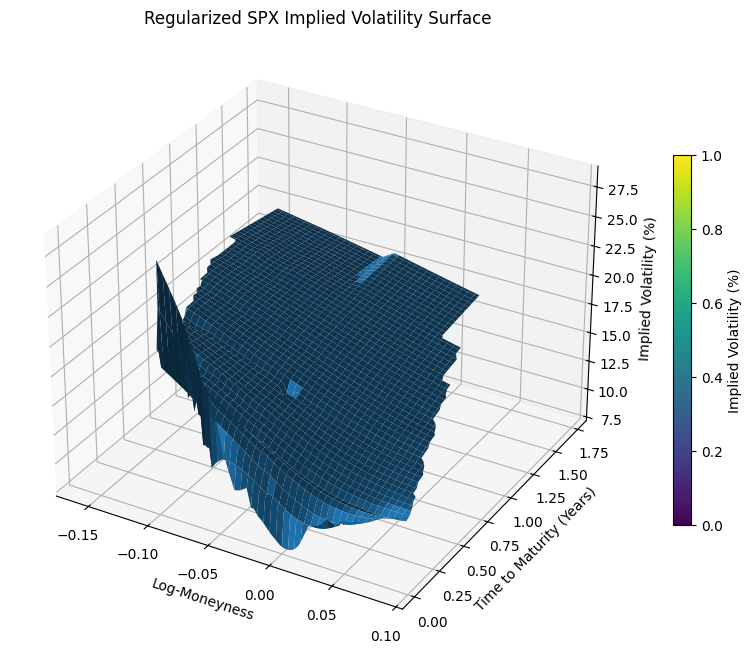

In [ ]:
fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    k_mesh_regular,
    T_mesh_regular,
    IV_regular * 100,
    edgecolor="none"
)

ax.set_xlabel("Log-Moneyness")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")
ax.set_title("Regularized SPX Implied Volatility Surface")

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Implied Volatility (%)"
)

plt.show()

In [ ]:
forward_regular = S0 * np.exp(
    (r - q) * T_mesh_regular
)

K_mesh_regular = (
    forward_regular * np.exp(k_mesh_regular)
)

In [ ]:
C_regular = np.full_like(
    IV_regular,
    np.nan
)

for i in range(T_mesh_regular.shape[0]):

    for j in range(T_mesh_regular.shape[1]):

        sigma = IV_regular[i, j]
        T = T_mesh_regular[i, j]
        K = K_mesh_regular[i, j]

        if np.isfinite(sigma) and T > 0:

            C_regular[i, j] = black_scholes_price(
                S0=S0,
                K=K,
                r=r,
                sigma=sigma,
                T=T,
                option_type="call"
            )

In [ ]:
bad_rows = []

for i in range(C_regular.shape[0]):

    valid = np.isfinite(C_regular[i])

    C_row = C_regular[i, valid]

    if len(C_row) > 1:

        if np.any(np.diff(C_row) > 0):
            bad_rows.append(i)

print("Total maturity rows:", C_regular.shape[0])
print("Rows violating C decreasing with K:", len(bad_rows))

Total maturity rows: 100
Rows violating C decreasing with K: 2


In [ ]:
for i in bad_rows:

    valid = np.isfinite(C_regular[i])

    K_row = K_mesh_regular[i, valid]
    C_row = C_regular[i, valid]

    diff_C = np.diff(C_row)

    print(
        f"T = {T_regular[i]:.6f}, "
        f"max increase = {np.max(diff_C):.6f}, "
        f"number of violations = {np.sum(diff_C > 0)}"
    )

T = 0.042922, max increase = 0.038647, number of violations = 1
T = 0.511416, max increase = 2.157165, number of violations = 1


In [ ]:
dC_dK_regular = np.full_like(C_regular, np.nan)
d2C_dK2_regular = np.full_like(C_regular, np.nan)

for i in range(C_regular.shape[0]):

    valid = np.isfinite(C_regular[i, :])

    K_row = K_mesh_regular[i, valid]
    C_row = C_regular[i, valid]

    if valid.sum() > 2:

        dC = np.gradient(
            C_row,
            K_row
        )

        d2C = np.gradient(
            dC,
            K_row
        )

        dC_dK_regular[i, valid] = dC
        d2C_dK2_regular[i, valid] = d2C

print(
    "C_K range:",
    np.nanmin(dC_dK_regular),
    np.nanmax(dC_dK_regular)
)

print(
    "C_KK range:",
    np.nanmin(d2C_dK2_regular),
    np.nanmax(d2C_dK2_regular)
)

C_K range: -1.4921284064792744 0.017100915671974803
C_KK range: -0.028424179793088273 0.03717362486778264


In [ ]:
valid_CKK = np.isfinite(d2C_dK2_regular)

negative_CKK = (
    d2C_dK2_regular[valid_CKK] < 0
)

print(
    "Negative C_KK points:",
    negative_CKK.sum()
)

print(
    "Total valid C_KK points:",
    valid_CKK.sum()
)

print(
    "Percentage negative:",
    100 * negative_CKK.mean()
)

Negative C_KK points: 793
Total valid C_KK points: 11234
Percentage negative: 7.058928253516111


In [ ]:
dC_dT_regular = np.full_like(C_regular, np.nan)

for j in range(C_regular.shape[1]):

    valid = np.isfinite(C_regular[:, j])

    T_col = T_regular[valid]
    C_col = C_regular[valid, j]

    if valid.sum() > 2:

        dC_dT_regular[valid, j] = np.gradient(
            C_col,
            T_col
        )

print(
    "C_T range:",
    np.nanmin(dC_dT_regular),
    np.nanmax(dC_dT_regular)
)

C_T range: -333.3489541840463 1732.523286300939


In [ ]:
dC_dT_fixedK = (
    dC_dT_regular
    - (r - q) * K_mesh_regular * dC_dK_regular
)
print(
    "C_T at fixed K range:",
    np.nanmin(dC_dT_fixedK),
    np.nanmax(dC_dT_fixedK)
)

C_T at fixed K range: -116.21552633694628 1914.8821555248965


In [ ]:
dupire_numerator = (
    dC_dT_fixedK
    + r * K_mesh_regular * dC_dK_regular
)

dupire_denominator = (
    0.5
    * K_mesh_regular**2
    * d2C_dK2_regular
)

In [ ]:
local_var = np.full_like(
    C_regular,
    np.nan
)

In [ ]:
valid_dupire = (
    np.isfinite(dupire_numerator)
    & np.isfinite(dupire_denominator)
    & (d2C_dK2_regular > 0)
    & (dupire_numerator > 0)
)

In [ ]:
local_var[valid_dupire] = (
    dupire_numerator[valid_dupire]
    / dupire_denominator[valid_dupire]
)

In [ ]:
local_vol = np.sqrt(local_var)

In [ ]:
print(
    "Local vol range:",
    np.nanmin(local_vol),
    np.nanmax(local_vol)
)

print(
    "Valid Dupire points:",
    np.sum(np.isfinite(local_vol))
)

print(
    "Total grid points:",
    local_vol.size
)

Local vol range: 0.015198018619884736 12.368954964117224
Valid Dupire points: 10430
Total grid points: 15000


In [ ]:
valid_local_vol = local_vol[np.isfinite(local_vol)]

percentiles = np.percentile(
    valid_local_vol,
    [1, 5, 25, 50, 75, 90, 95, 99]
)

for p, value in zip(
    [1, 5, 25, 50, 75, 90, 95, 99],
    percentiles
):
    print(f"{p}%: {value:.4f}")


print("Local vol > 1.0:",
      np.sum(valid_local_vol > 1.0))

print("Local vol > 2.0:",
      np.sum(valid_local_vol > 2.0))

print("Total valid:",
      len(valid_local_vol))

1%: 0.0477
5%: 0.0964
25%: 0.1458
50%: 0.1813
75%: 0.2158
90%: 0.2546
95%: 0.2892
99%: 0.4671
Local vol > 1.0: 16
Local vol > 2.0: 4
Total valid: 10430


In [ ]:
positive_CKK = d2C_dK2_regular[
    np.isfinite(d2C_dK2_regular)
    & (d2C_dK2_regular > 0)
]

ckk_percentiles = np.percentile(
    positive_CKK,
    [0.1, 1, 5, 25, 50, 75, 95, 99]
)

for p, value in zip(
    [0.1, 1, 5, 25, 50, 75, 95, 99],
    ckk_percentiles
):
    print(f"{p}%: {value:.8f}")

0.1%: 0.00000705
1%: 0.00004146
5%: 0.00010734
25%: 0.00019222
50%: 0.00028287
75%: 0.00050267
95%: 0.00128630
99%: 0.00332110


In [ ]:
ckk_threshold = np.percentile(
    positive_CKK,
    1
)

print("C_KK threshold:", ckk_threshold)

C_KK threshold: 4.146374650739046e-05


In [ ]:
stable_dupire = (
    np.isfinite(dupire_numerator)
    & np.isfinite(dupire_denominator)
    & (dupire_numerator > 0)
    & (d2C_dK2_regular > ckk_threshold)
)

In [ ]:
local_vol_stable = np.full_like(
    C_regular,
    np.nan
)

local_vol_stable[stable_dupire] = np.sqrt(
    dupire_numerator[stable_dupire]
    /
    dupire_denominator[stable_dupire]
)

valid_stable = local_vol_stable[
    np.isfinite(local_vol_stable)
]

print(
    "Stable local vol range:",
    valid_stable.min(),
    valid_stable.max()
)

print(
    "Stable points:",
    len(valid_stable)
)

print(
    "Median:",
    np.median(valid_stable)
)

print(
    "99th percentile:",
    np.percentile(valid_stable, 99)
)

Stable local vol range: 0.015198018619884736 0.6541089031245373
Stable points: 10325
Median: 0.1809762470075466
99th percentile: 0.38045066729452515


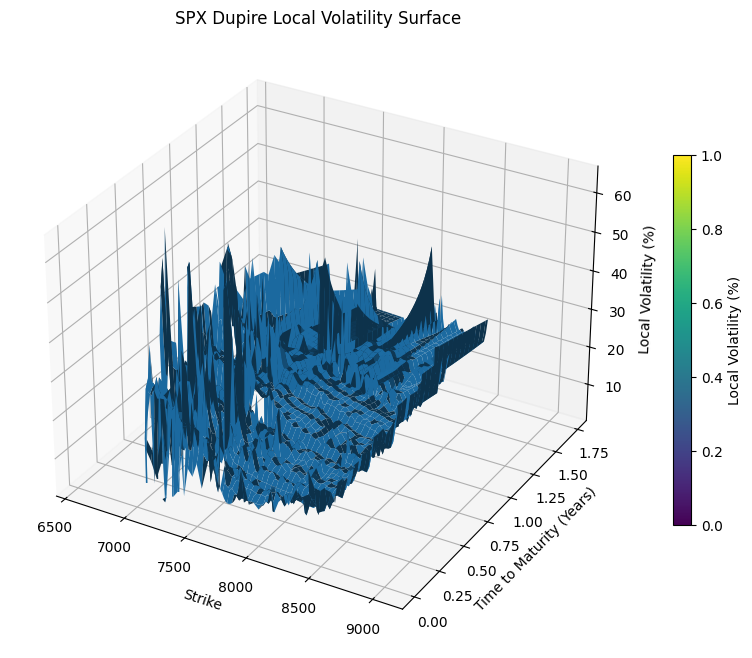

In [ ]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    K_mesh_regular,
    T_mesh_regular,
    local_vol_stable * 100,
    edgecolor="none"
)

ax.set_xlabel("Strike")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Local Volatility (%)")

ax.set_title("SPX Dupire Local Volatility Surface")

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Local Volatility (%)"
)

plt.show()